In [1]:
import matplotlib.pyplot as plt 
import numpy as np
import seaborn as sns
import pandas as pd

from scipy.stats import ttest_ind, mannwhitneyu

from src.config import DADOS_ORIGINAIS, DADOS_LIMPOS
from src.graficos import PALETTE

sns.set_theme(palette='bright')

In [2]:
df = pd.read_csv(DADOS_ORIGINAIS)
df.head(10)

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678
5,843786,M,12.45,15.70,82.57,477.1,0.12780,0.17000,0.15780,0.08089,...,15.47,23.75,103.40,741.6,0.1791,0.5249,0.5355,0.1741,0.3985,0.12440
6,844359,M,18.25,19.98,119.60,1040.0,0.09463,0.10900,0.11270,0.07400,...,22.88,27.66,153.20,1606.0,0.1442,0.2576,0.3784,0.1932,0.3063,0.08368
7,84458202,M,13.71,20.83,90.20,577.9,0.11890,0.16450,0.09366,0.05985,...,17.06,28.14,110.60,897.0,0.1654,0.3682,0.2678,0.1556,0.3196,0.11510
8,844981,M,13.00,21.82,87.50,519.8,0.12730,0.19320,0.18590,0.09353,...,15.49,30.73,106.20,739.3,0.1703,0.5401,0.5390,0.2060,0.4378,0.10720
9,84501001,M,12.46,24.04,83.97,475.9,0.11860,0.23960,0.22730,0.08543,...,15.09,40.68,97.65,711.4,0.1853,1.0580,1.1050,0.2210,0.4366,0.20750


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

In [4]:
df.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [5]:
df.describe(exclude='number')

,diagnosis
count,569
unique,2
top,B
freq,357


In [6]:
df['diagnosis'].value_counts(normalize=True)

diagnosis
B    0.627417
M    0.372583
Name: proportion, dtype: float64

In [7]:
df[df.duplicated()]


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst


In [8]:
df[df.duplicated('id')]

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst


In [9]:
df = df.drop(columns=['id'])

In [10]:
df = df.reindex(sorted(df.columns), axis=1)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   area_mean                569 non-null    float64
 1   area_se                  569 non-null    float64
 2   area_worst               569 non-null    float64
 3   compactness_mean         569 non-null    float64
 4   compactness_se           569 non-null    float64
 5   compactness_worst        569 non-null    float64
 6   concave points_mean      569 non-null    float64
 7   concave points_se        569 non-null    float64
 8   concave points_worst     569 non-null    float64
 9   concavity_mean           569 non-null    float64
 10  concavity_se             569 non-null    float64
 11  concavity_worst          569 non-null    float64
 12  diagnosis                569 non-null    str    
 13  fractal_dimension_mean   569 non-null    float64
 14  fractal_dimension_se     569 non-null

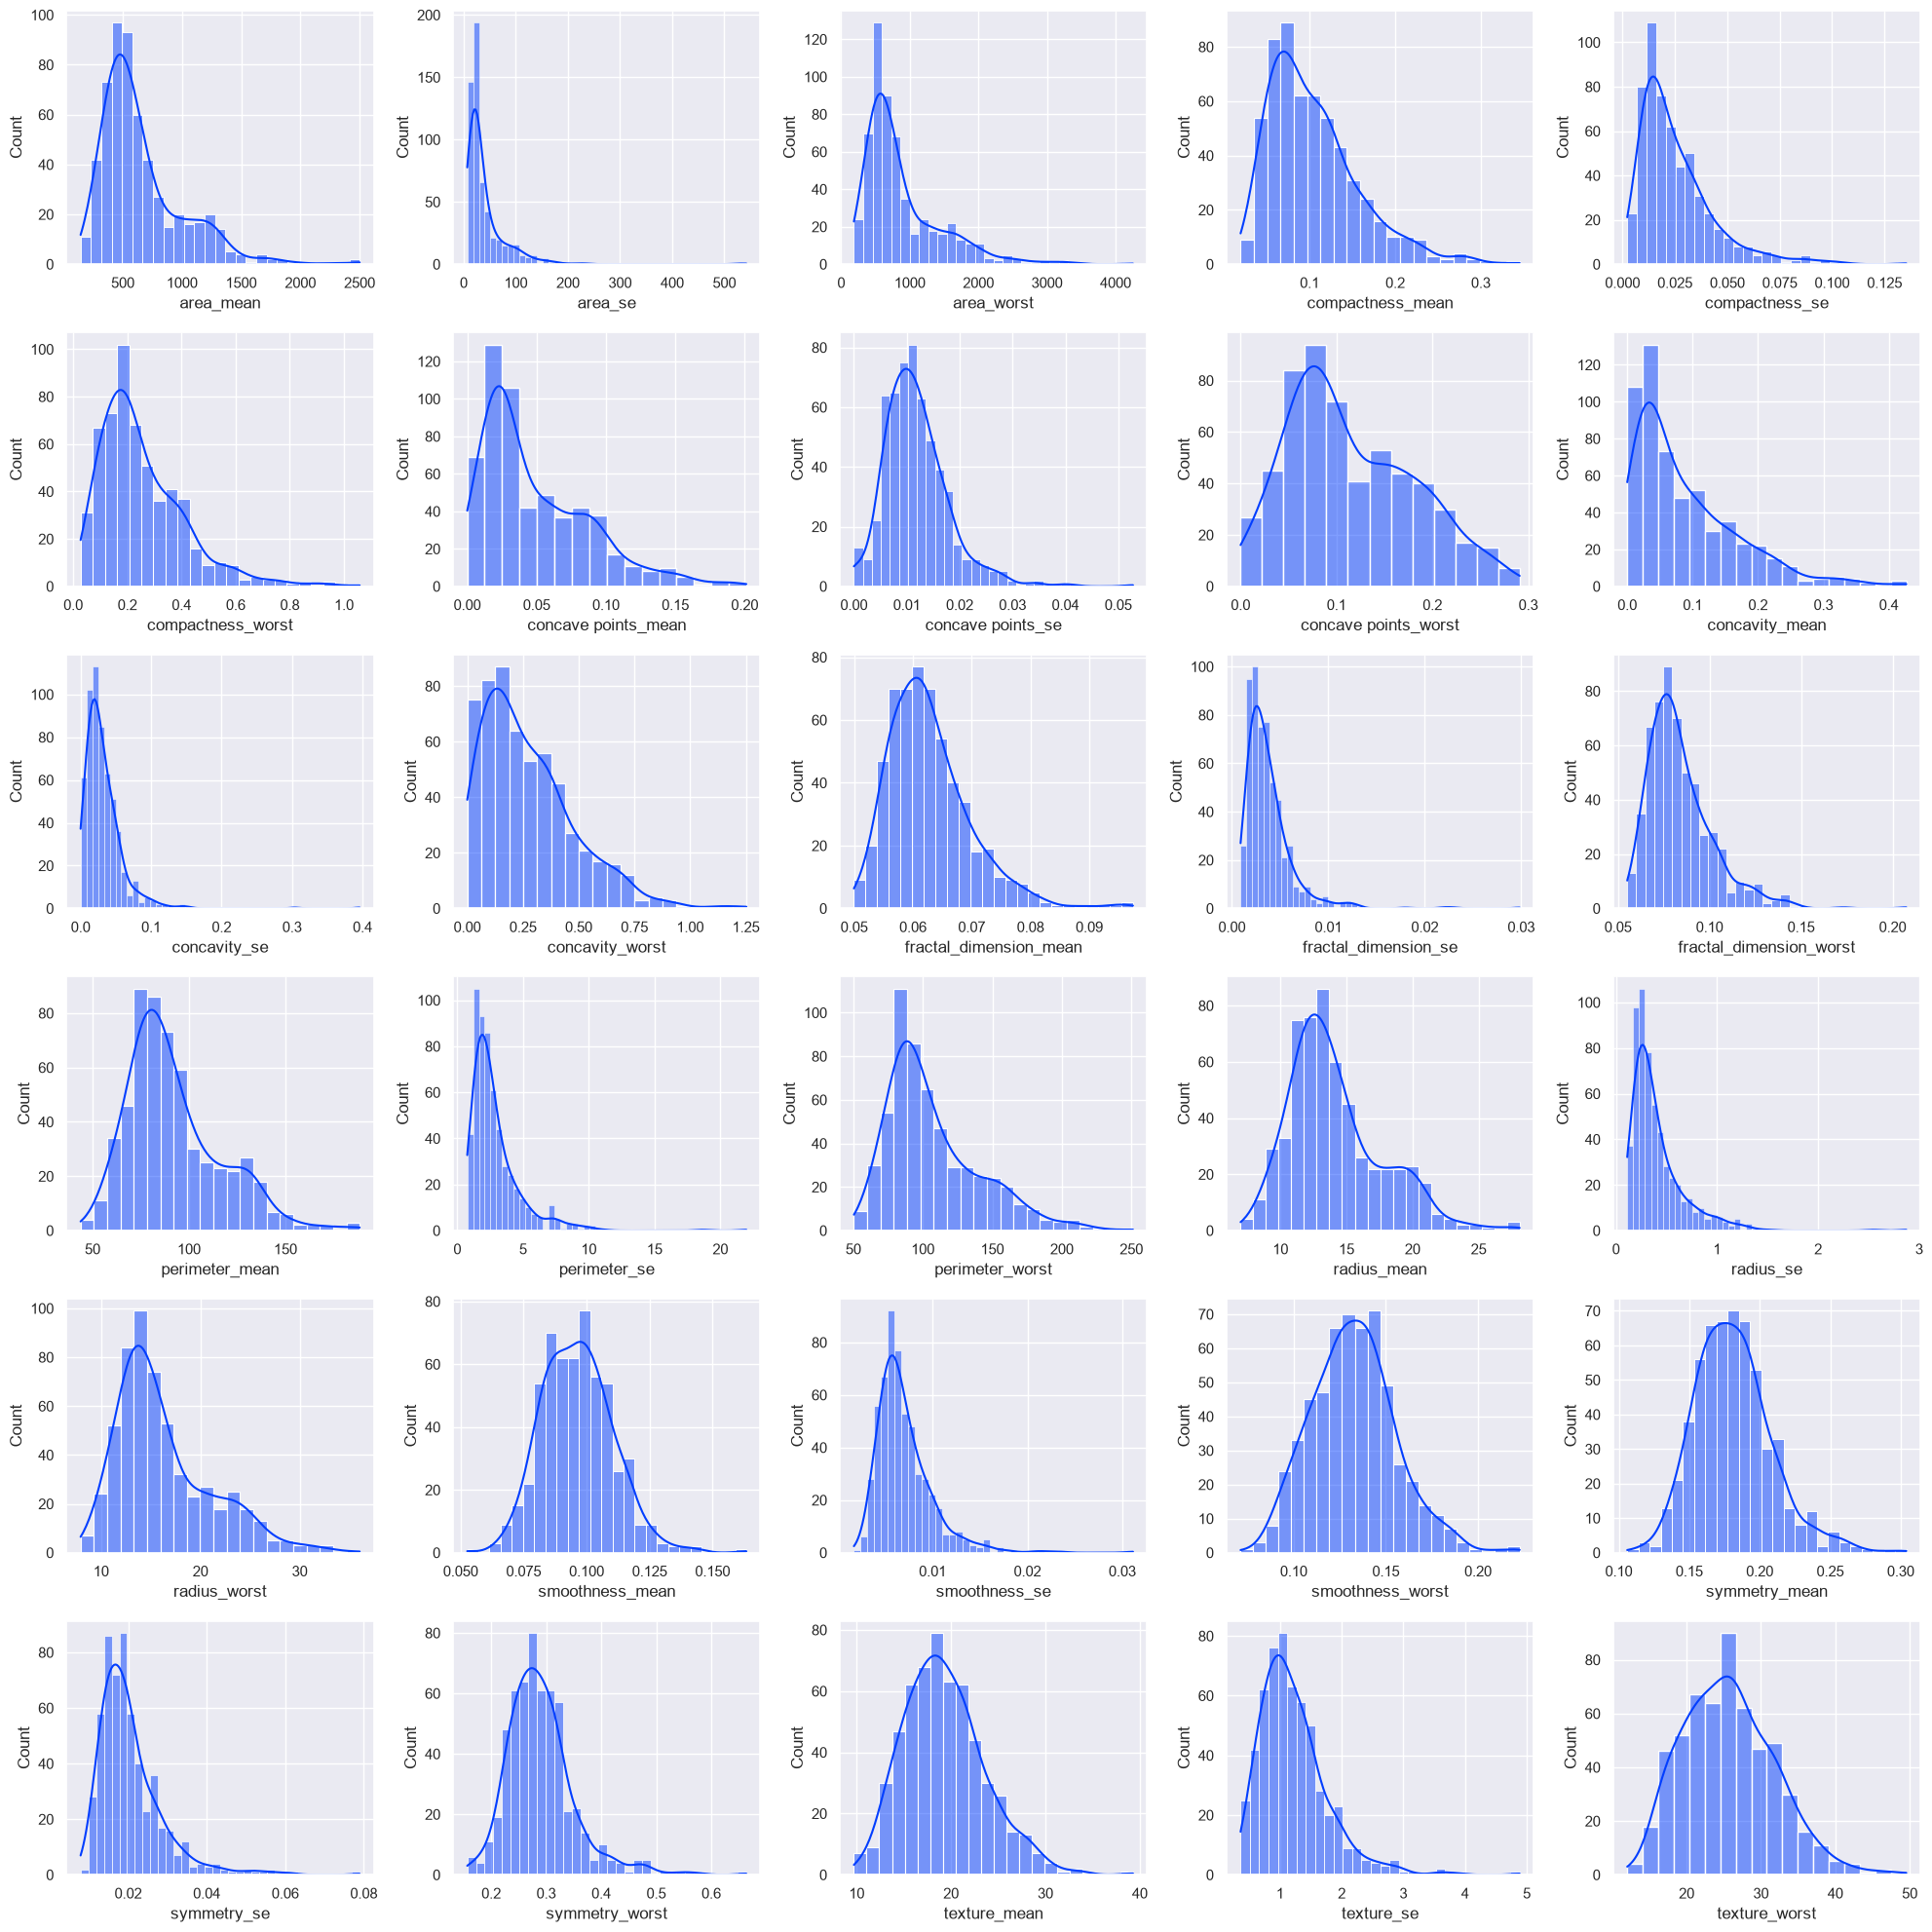

In [11]:
fig, axs = plt.subplots(6, 5, figsize=(20, 20))

for ax, colun in zip(axs.flatten(), df.select_dtypes(include='number').columns):
    sns.histplot(data=df, x=colun, ax=ax, kde=True)

plt.tight_layout()
plt.show()

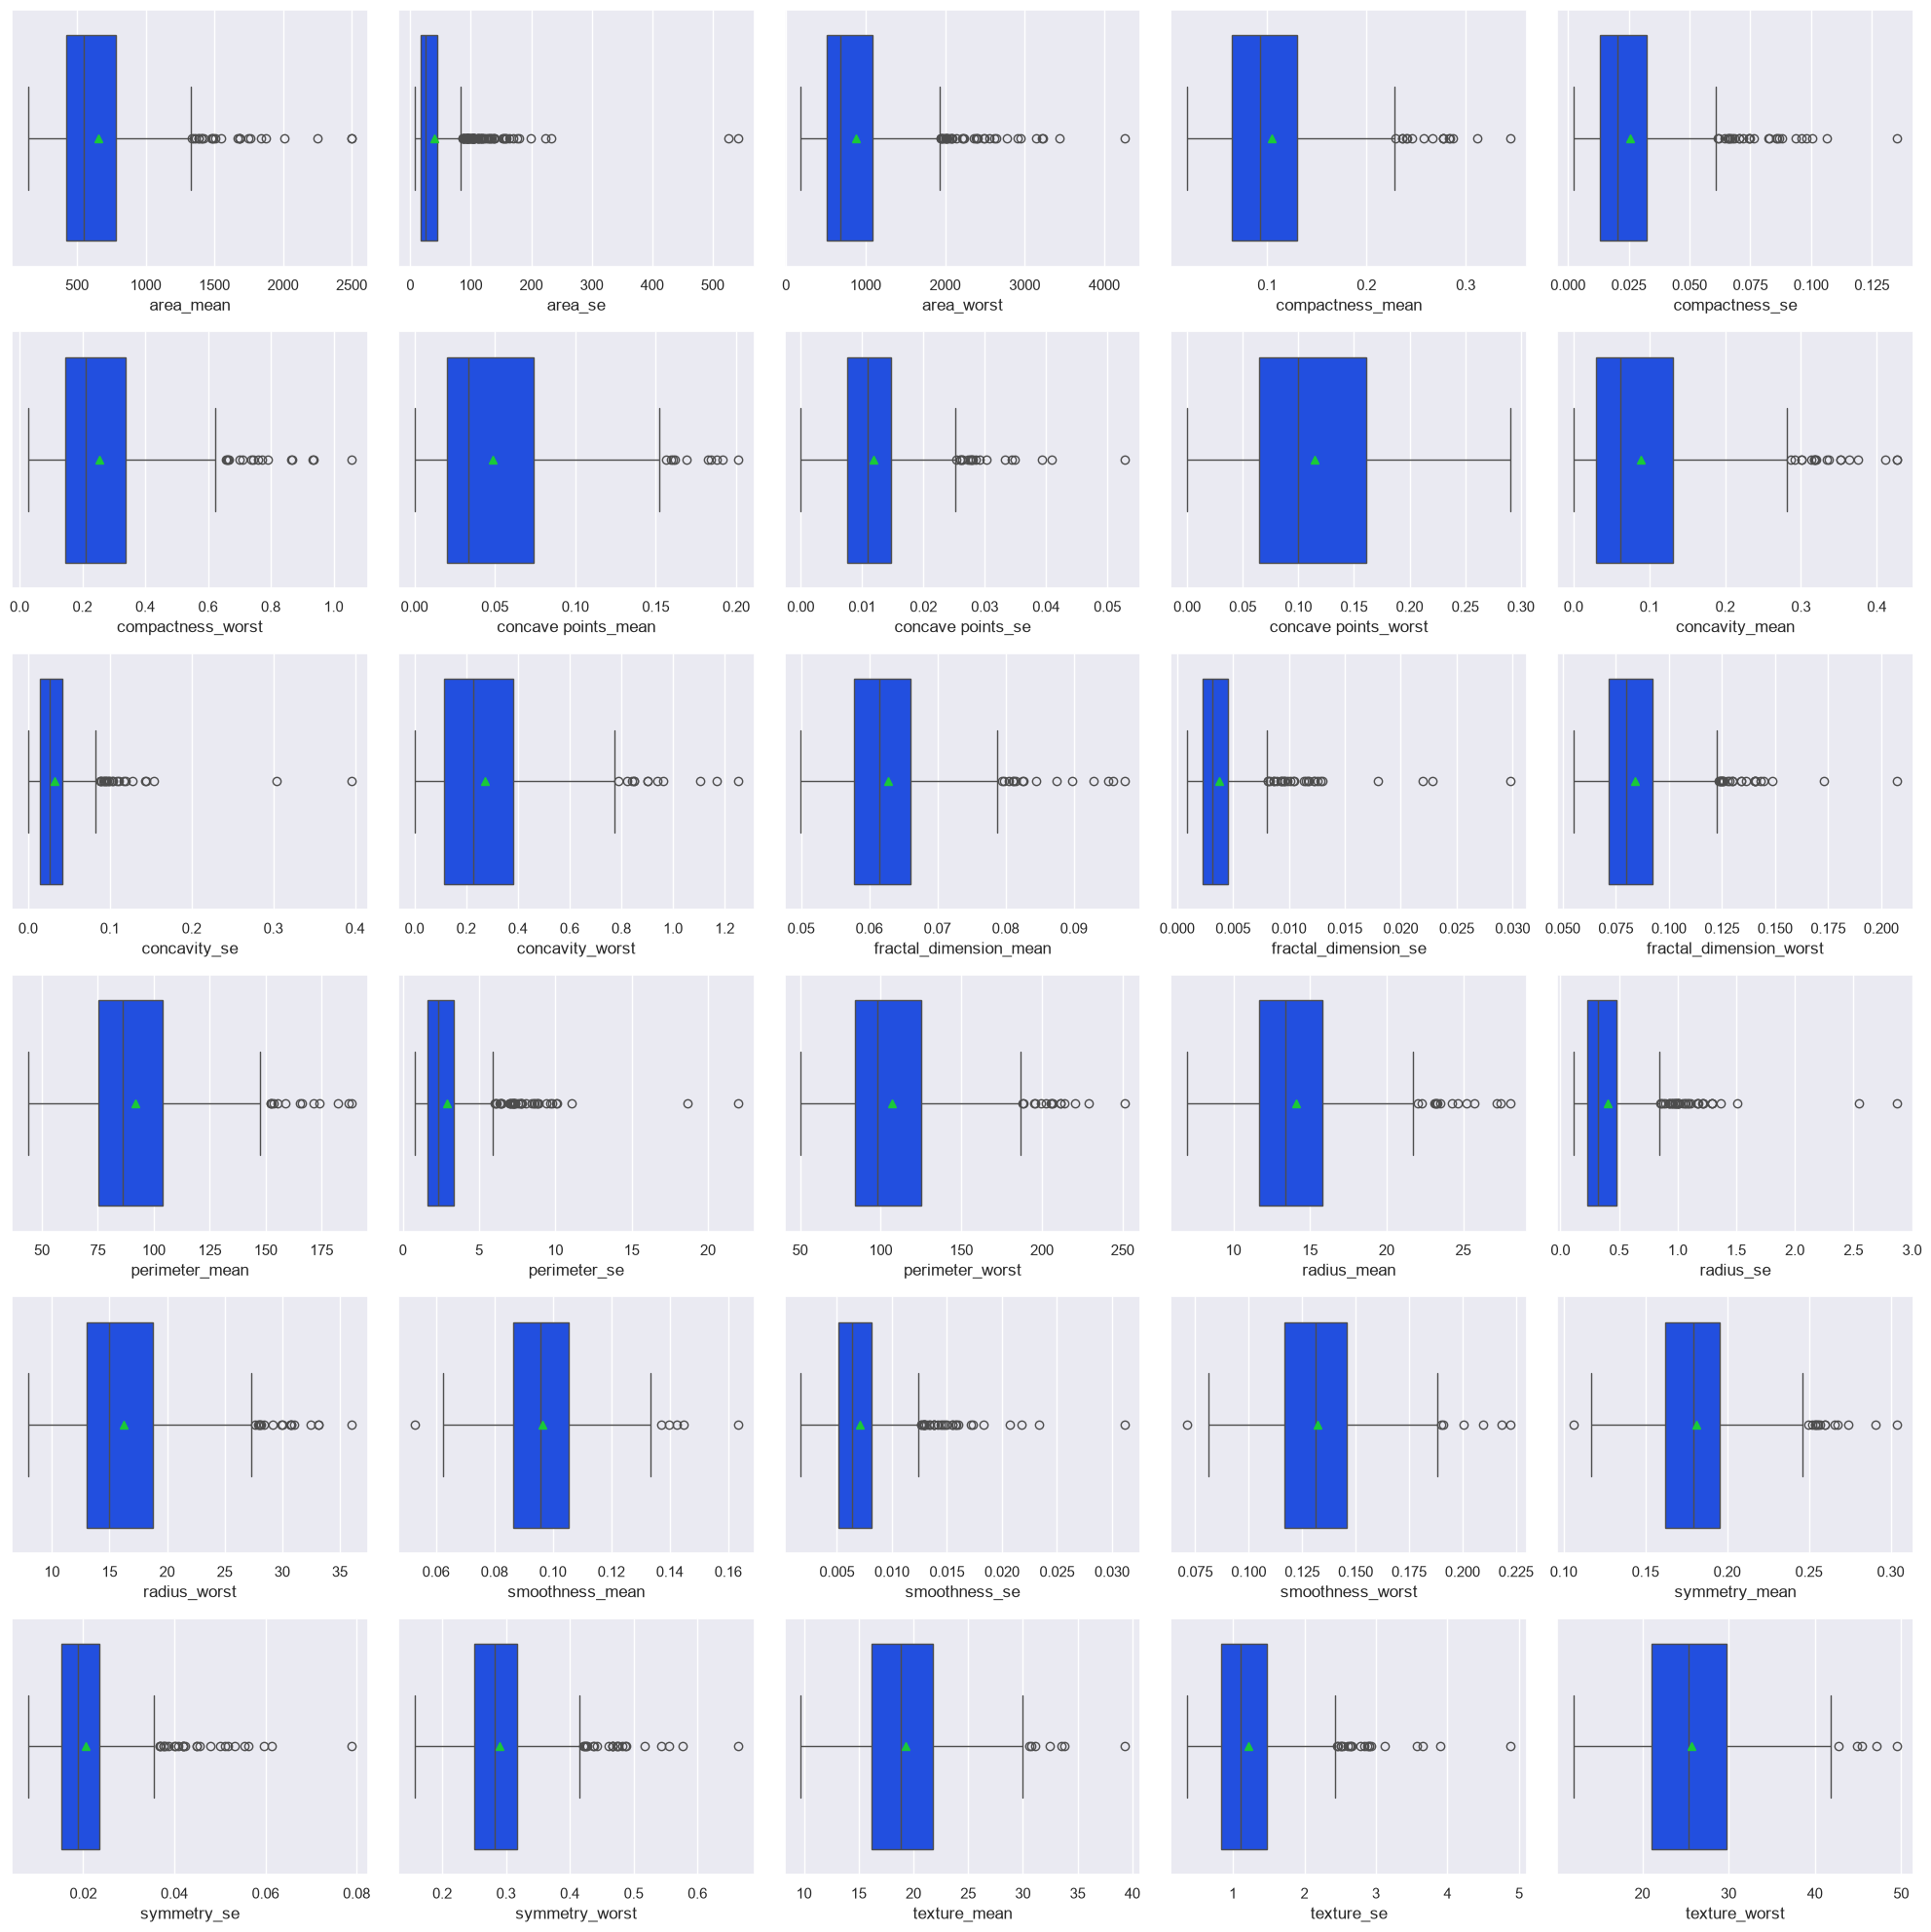

In [12]:
fig, axs = plt.subplots(6, 5, figsize=(20, 20))

for ax, colun in zip(axs.flatten(), df.select_dtypes(include='number').columns):
    sns.boxplot(data=df, x=colun, ax=ax, showmeans=True)

plt.tight_layout()
plt.show()

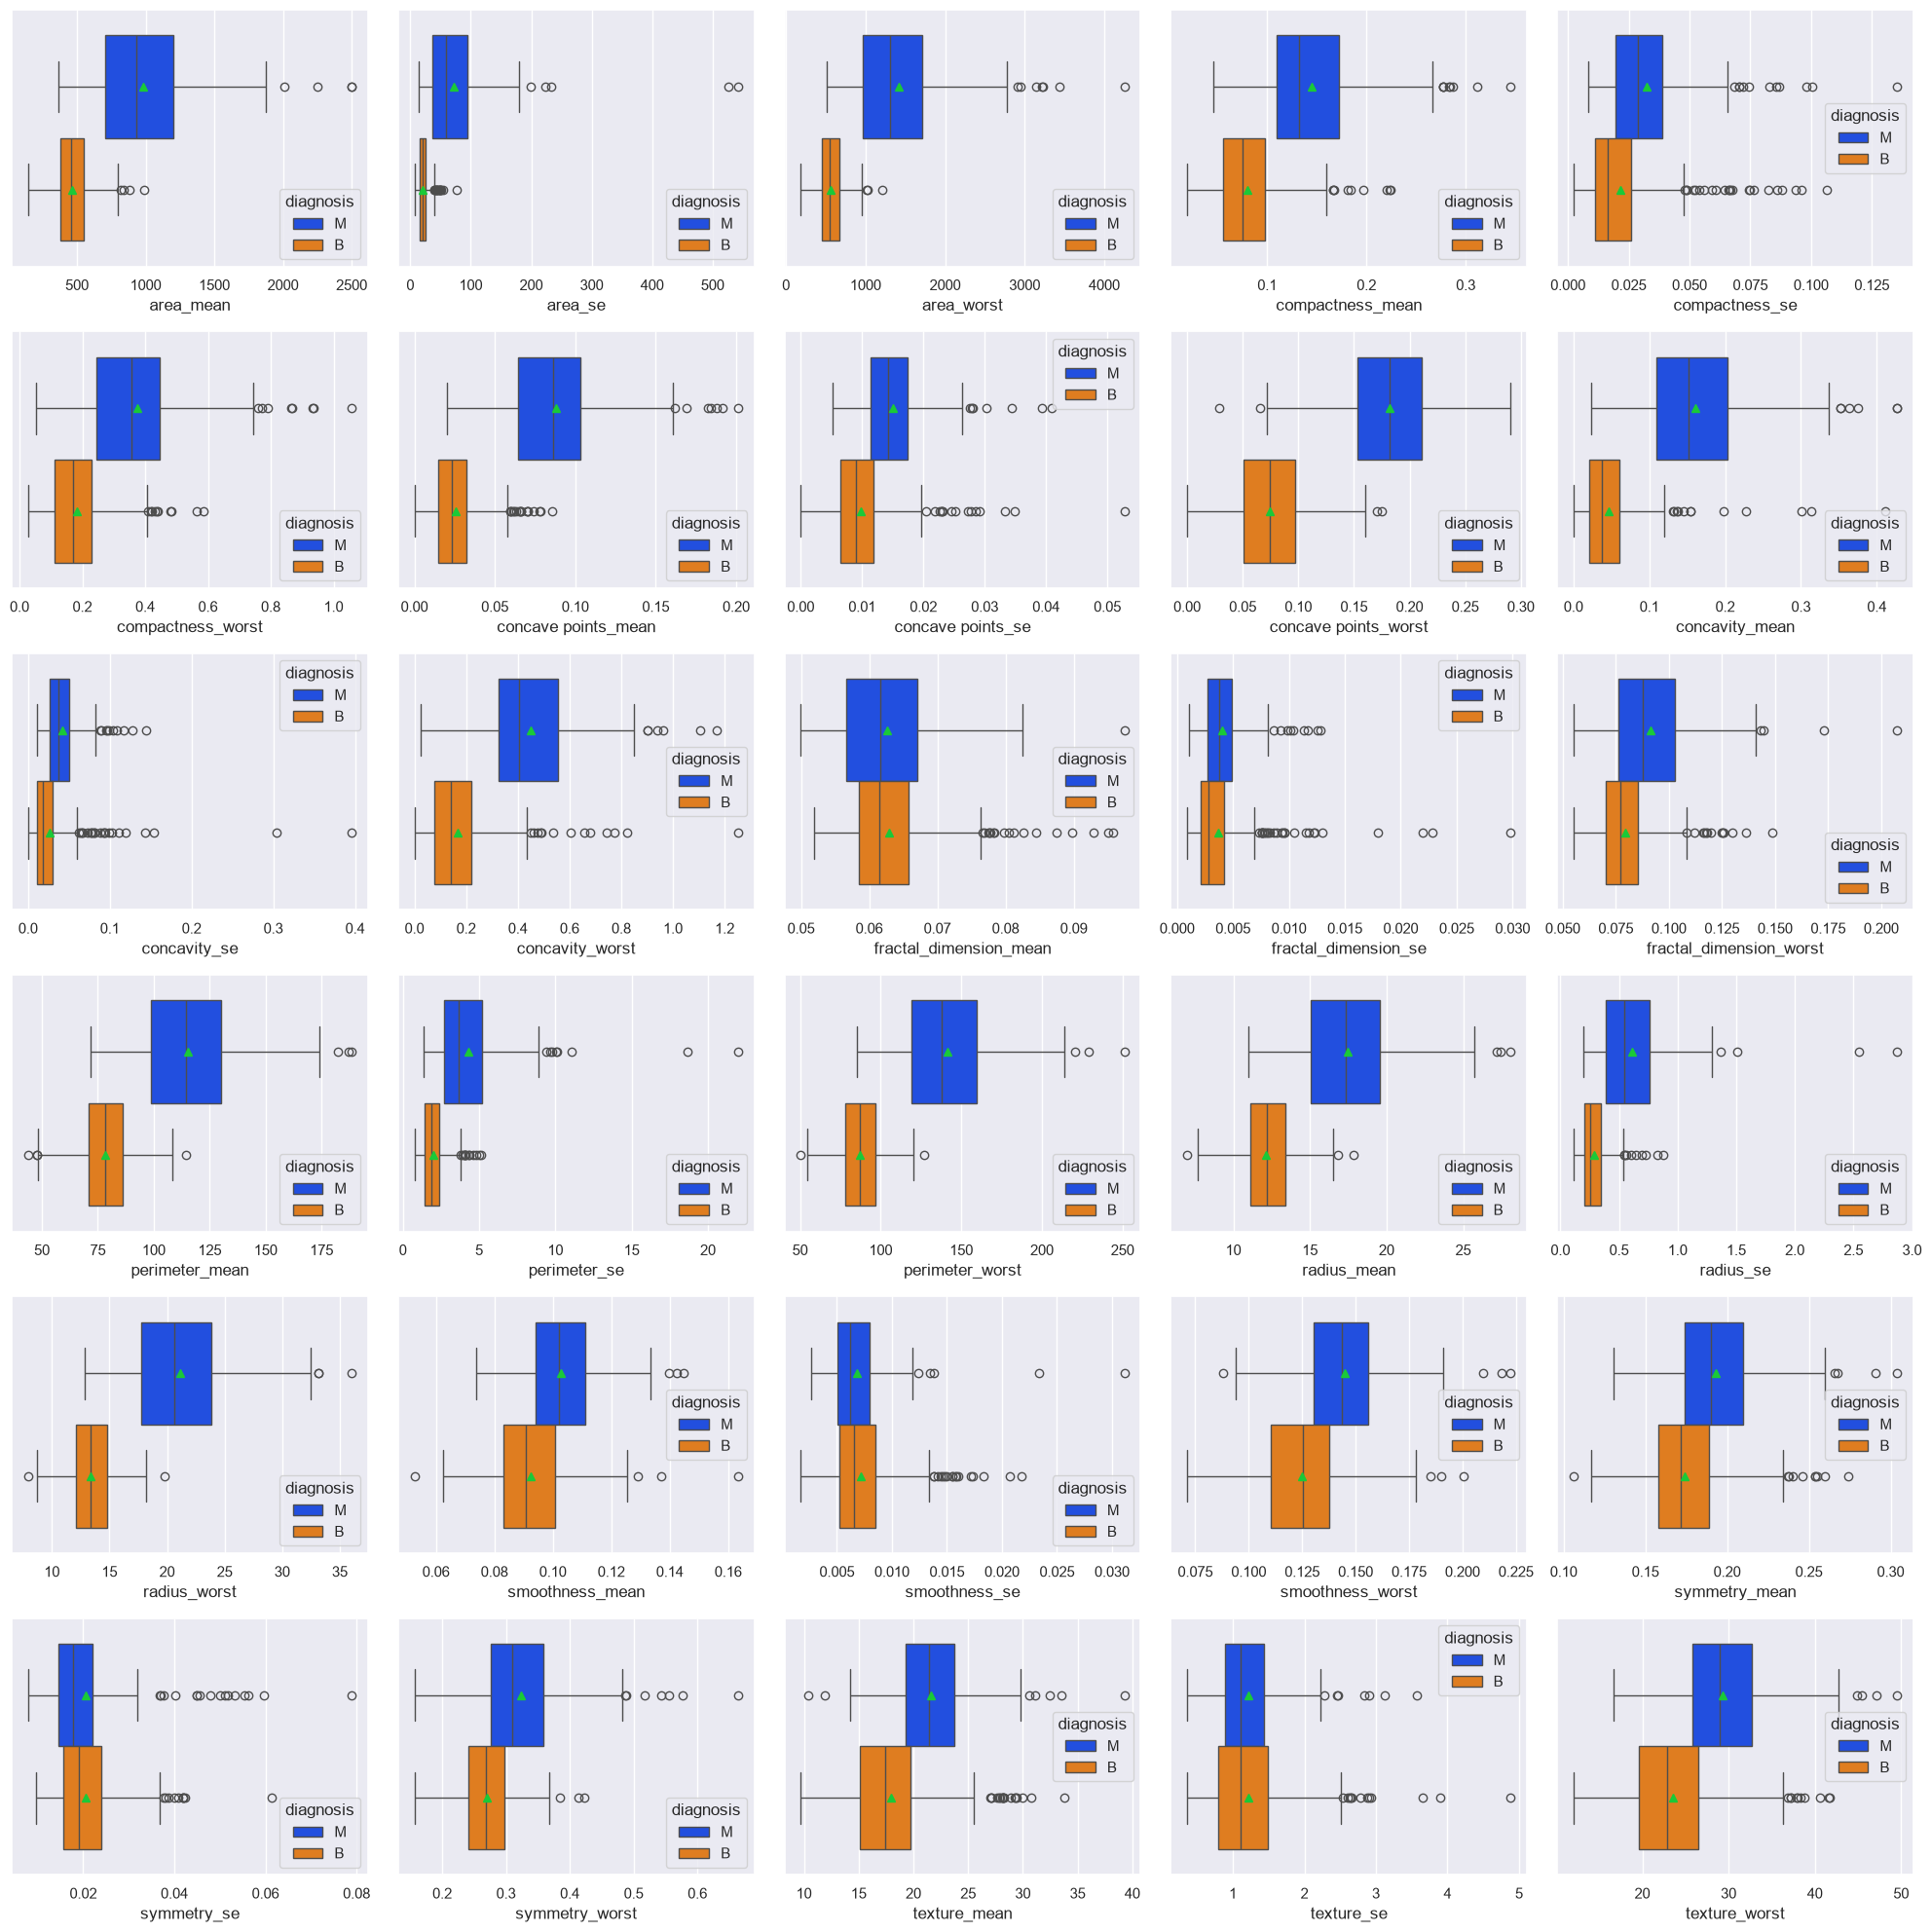

In [13]:
fig, axs = plt.subplots(6, 5, figsize=(20, 20))

for ax, colun in zip(axs.flatten(), df.select_dtypes(include='number').columns):
    sns.boxplot(data=df, x=colun, ax=ax, showmeans=True, hue='diagnosis')

plt.tight_layout()
plt.show()

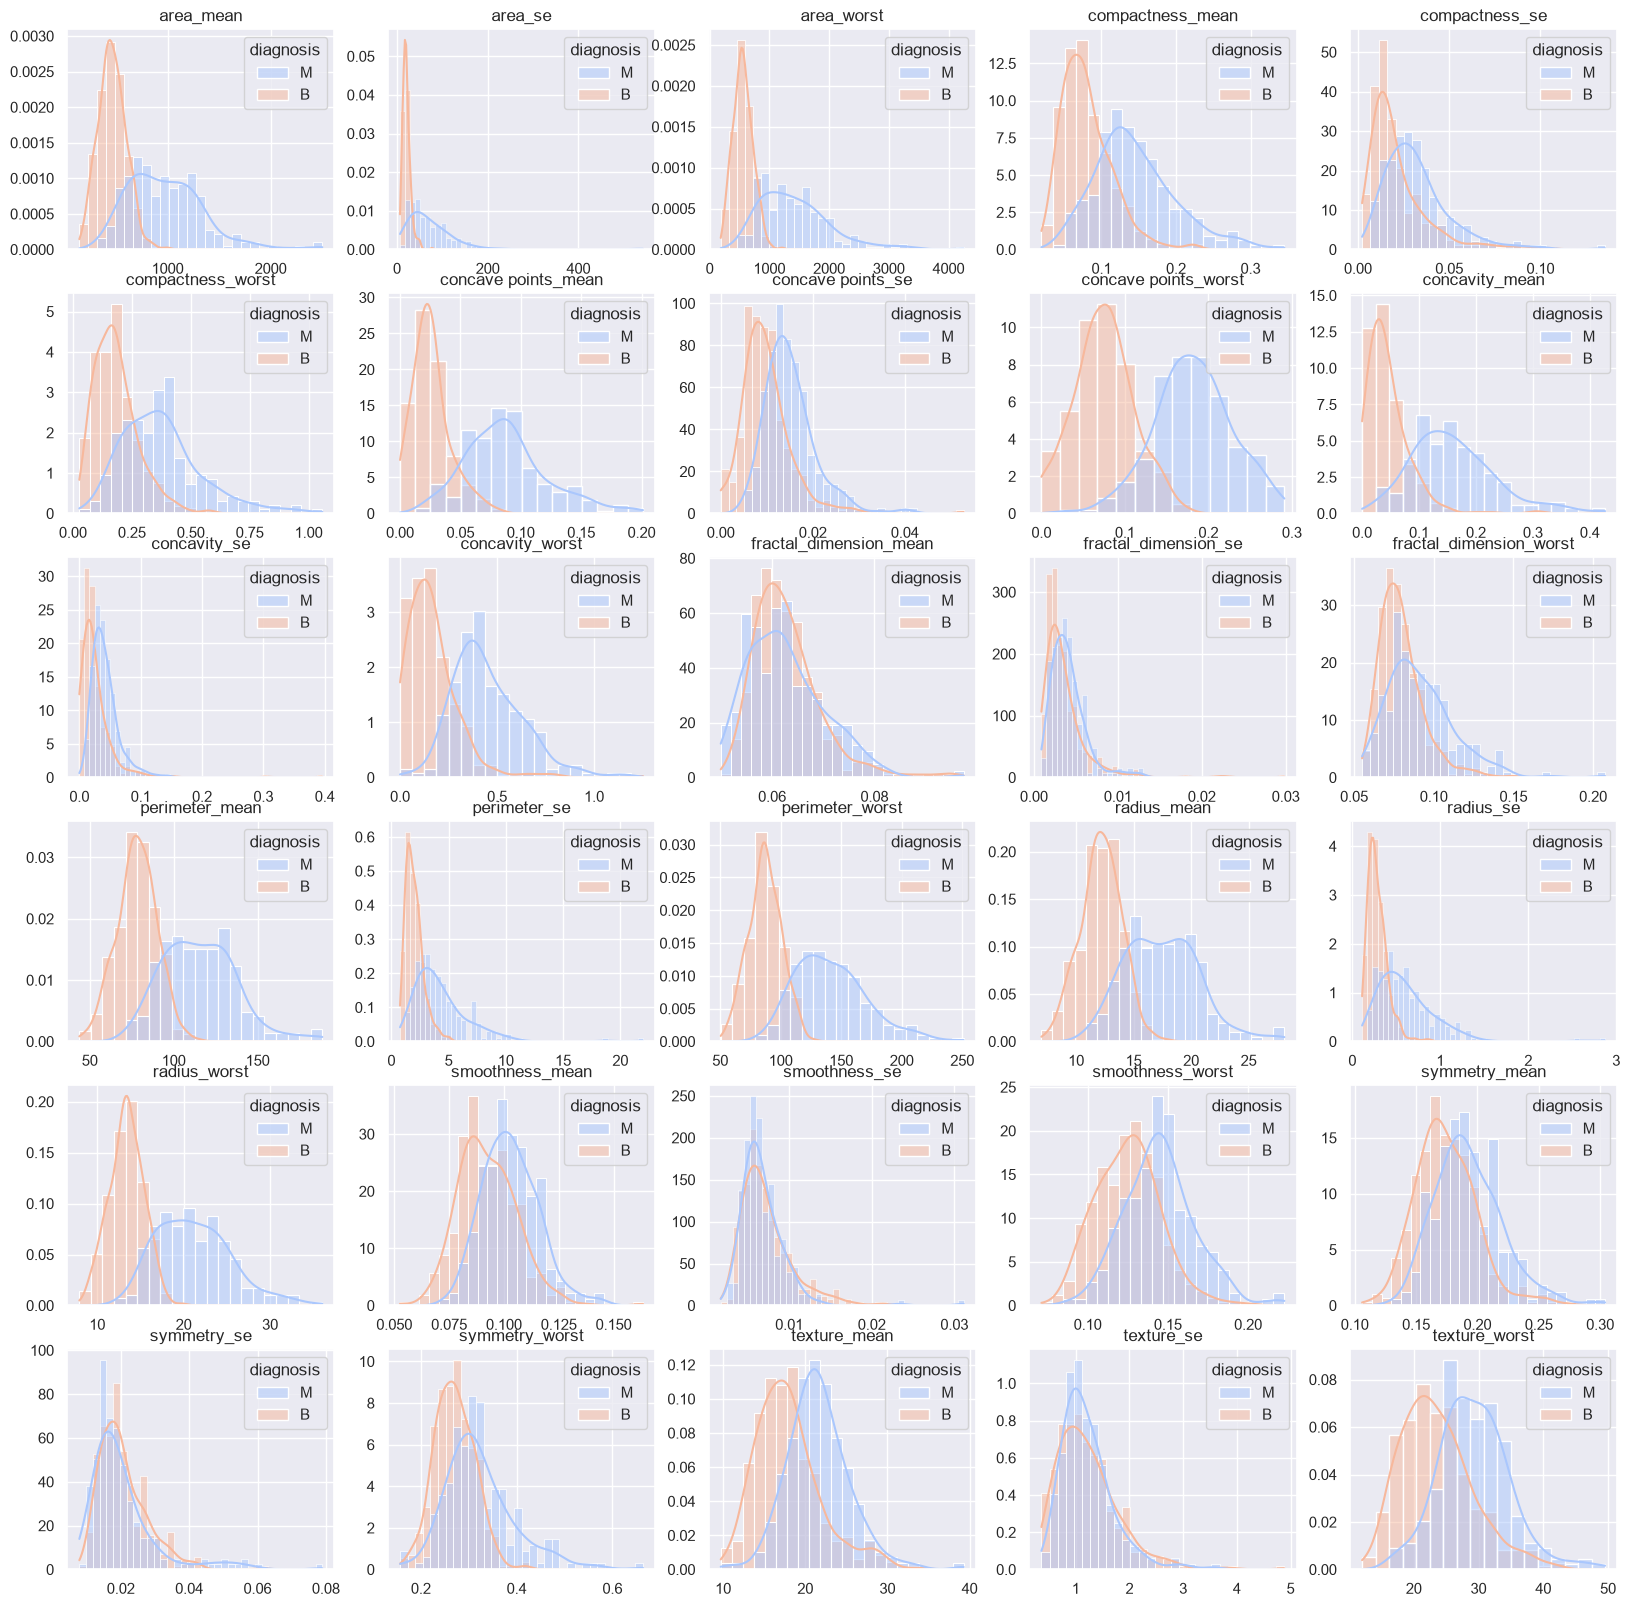

In [14]:
fig, axs = plt.subplots(6, 5, figsize=(20, 20))

for ax, colun in zip(axs.flatten(), df.select_dtypes(include='number').columns):
    sns.histplot(data=df, x=colun, hue='diagnosis', ax=ax, palette=PALETTE, kde=True, stat='density', common_norm=False)
    ax.set_title(colun)
    ax.set_xlabel('')
    ax.set_ylabel('')



In [15]:
colunas_numericas = df.select_dtypes(include='number').columns.to_list()

analise_colunas_ttest = {}
analise_colunas_mw ={}

coluna_target = 'diagnosis'

In [16]:
classes = df[coluna_target].unique()
classes

<ArrowStringArray>
['M', 'B']
Length: 2, dtype: str

In [17]:
alfa = 0.05

In [18]:
df.groupby(coluna_target).get_group(classes[0])['area_worst']

0      2019.0
1      1956.0
2      1709.0
3       567.7
4      1575.0
        ...  
563    1819.0
564    2027.0
565    1731.0
566    1124.0
567    1821.0
Name: area_worst, Length: 212, dtype: float64

In [19]:
agrupamento = df.groupby(coluna_target)

In [20]:
for colun in colunas_numericas:
    grupo1 = agrupamento.get_group(classes[0])[colun]
    grupo2 = agrupamento.get_group(classes[1])[colun]

    t_stat, pvalue_t = ttest_ind(grupo1, grupo2)

    mw_stat, pvalue_mw = mannwhitneyu(grupo1, grupo2)

    analise_colunas_ttest[colun] = {
        'pvalue': pvalue_t,
        'estatistica': t_stat,
        'rejeita_hipotese_nula': pvalue_t < alfa
    }

    analise_colunas_mw[colun] = {
        'pvalue': pvalue_mw,
        'estatistica': mw_stat,
        'rejeita_hipotese_nula': pvalue_mw < alfa
    }
    
    

In [21]:
pd.DataFrame(analise_colunas_ttest).T.sort_values(by='pvalue')

,pvalue,estatistica,rejeita_hipotese_nula
concave points_worst,0.0,31.054555,True
perimeter_worst,0.0,29.965717,True
concave points_mean,0.0,29.354319,True
radius_worst,0.0,29.339082,True
perimeter_mean,0.0,26.405213,True
area_worst,0.0,25.72159,True
radius_mean,0.0,25.435822,True
area_mean,0.0,23.938687,True
concavity_mean,0.0,23.103963,True
concavity_worst,0.0,20.897175,True


In [22]:
df.to_parquet(DADOS_LIMPOS, index=False)